# 2.5 Υπολογισμός μετρικών αξιολόγησης

In [ ]:
!pip install -q "transformers<5" evaluate sacrebleu unbabel-comet

Note: you may need to restart the kernel to use updated packages.


In [1]:
import gc
import os

os.environ["USE_TF"] = "0"
os.environ["USE_FLAX"] = "0"

import evaluate
import matplotlib.pyplot as plt
import pandas as pd
import torch
from huggingface_hub import login

## Φόρτωση δεδομένων

In [2]:
# FLORES
with open("facebook_nllb_200_translations.txt", "r", encoding="utf-8") as f:
    fb_nllb = f.read().splitlines()

with open("Helsinki_NLP_Translations.txt", "r", encoding="utf-8") as f:
    helsinki_nlp = f.read().splitlines()

with open("Flores_ell.txt", "r", encoding="utf-8") as f:
    source = f.read().splitlines()

with open("Flores_eng.txt", "r", encoding="utf-8") as f:
    ref = f.read().splitlines()

# Test set
with open("facebook_nllb_200_test_translations.txt", "r", encoding="utf-8") as f:
    fb_nllb_test = f.read().splitlines()

with open("Helsinki_NLP_Test_Translations.txt", "r", encoding="utf-8") as f:
    helsinki_nlp_test = f.read().splitlines()

with open("data/test.el", "r", encoding="utf-8") as f:
    test_source = f.read().splitlines()

with open("data/test.en", "r", encoding="utf-8") as f:
    test_ref = f.read().splitlines()

# Εμπορικά Συστήματα
with open("azure_translations.en", "r", encoding="utf-8") as f:
    azure_translations = f.read().splitlines()

with open("deepl_translations.en", "r", encoding="utf-8") as f:
    deepl_translations = f.read().splitlines()

with open("google_translations.en", "r", encoding="utf-8") as f:
    google_translations = f.read().splitlines()


## 2.5.1 BLEU και chrF

In [3]:
BLEU = evaluate.load("sacrebleu")
CHRF = evaluate.load("chrf")

### facebook/nllb-200-distilled-600M

In [4]:
bleu_nllb_flores = BLEU.compute(predictions=fb_nllb, references=[[r] for r in ref])["score"]
chrf_nllb_flores = CHRF.compute(predictions=fb_nllb, references=[[r] for r in ref])["score"]

print("FLORES BLEU:", bleu_nllb_flores)
print("FLORES chrF:", chrf_nllb_flores)

FLORES BLEU: 33.967426994433815
FLORES chrF: 59.75878770624221


In [5]:
bleu_nllb_test = BLEU.compute(predictions=fb_nllb_test, references=[[r] for r in test_ref])["score"]
chrf_nllb_test = CHRF.compute(predictions=fb_nllb_test, references=[[r] for r in test_ref])["score"]

print("Test set BLEU:", bleu_nllb_test)
print("Test set chrF:", chrf_nllb_test)

Test set BLEU: 27.740281863867192
Test set chrF: 51.55975215980399


### Helsinki-NLP/opus-mt-grk-en

In [6]:
bleu_helsinki_flores = BLEU.compute(predictions=helsinki_nlp, references=[[r] for r in ref])["score"]
chrf_helsinki_flores = CHRF.compute(predictions=helsinki_nlp, references=[[r] for r in ref])["score"]

print("FLORES BLEU:", bleu_helsinki_flores)
print("FLORES chrF:", chrf_helsinki_flores)

FLORES BLEU: 27.383005815157855
FLORES chrF: 56.11597367050298


In [7]:
bleu_helsinki_test = BLEU.compute(predictions=helsinki_nlp_test, references=[[r] for r in test_ref])["score"]
chrf_helsinki_test = CHRF.compute(predictions=helsinki_nlp_test, references=[[r] for r in test_ref])["score"]

print("Test set BLEU:", bleu_helsinki_test)
print("Test set chrF:", chrf_helsinki_test)

Test set BLEU: 32.624642502411895
Test set chrF: 55.36343887612235


### Αzure

In [8]:
bleu_azure = BLEU.compute(predictions=azure_translations, references=[[r] for r in test_ref])["score"]
chrf_azure = CHRF.compute(predictions=azure_translations, references=[[r] for r in test_ref])["score"]

print("Azure BLEU:", bleu_azure )
print("Azure chrF:", chrf_azure)

Azure BLEU: 35.573573834984074
Azure chrF: 59.19295609105043


### Deepl

In [9]:
bleu_deepl = BLEU.compute(predictions=deepl_translations, references=[[r] for r in test_ref])["score"]
chrf_deepl = CHRF.compute(predictions=deepl_translations, references=[[r] for r in test_ref])["score"]

print("Deepl BLEU:", bleu_deepl )
print("Deepl chrF:", chrf_deepl )

Deepl BLEU: 31.539470417672703
Deepl chrF: 57.085600675158155


### Google

In [10]:
bleu_google = BLEU.compute(predictions=google_translations, references=[[r] for r in test_ref])["score"]
chrf_google = CHRF.compute(predictions=google_translations, references=[[r] for r in test_ref])["score"]

print("Google BLEU:", bleu_google)
print("Google chrF:", chrf_google)

Google BLEU: 42.66185928307693
Google chrF: 63.64608140415024


## 2.5.2 COMET

In [14]:
login()
comet = evaluate.load("comet")

Fetching 5 files:   0%|          | 0/5 [00:00<?, ?it/s]

Lightning automatically upgraded your loaded checkpoint from v1.8.3.post1 to v2.6.6. To apply the upgrade to your files permanently, run `python -m pytorch_lightning.utilities.upgrade_checkpoint ../../../.cache/huggingface/hub/models--Unbabel--wmt22-comet-da/snapshots/2760a223ac957f30acfb18c8aa649b01cf1d75f2/checkpoints/model.ckpt`
Encoder model frozen.
/Users/raftisk/Projects/sandbox/machine-translation/.venv-mt/lib/python3.11/site-packages/pytorch_lightning/core/saving.py:216: Found keys that are not in the model state dict but in the checkpoint: ['encoder.model.embeddings.position_ids']


In [15]:
gpus = 1 if (torch.cuda.is_available() or torch.backends.mps.is_available()) else 0

# FLORES
comet_nllb_flores = comet.compute(predictions=fb_nllb, references=ref, sources=source, gpus=gpus)["mean_score"]
comet_helsinki_flores = comet.compute(predictions=helsinki_nlp, references=ref, sources=source, gpus=gpus)["mean_score"]

print("FLORES Facebook NLLB COMET:", comet_nllb_flores)
print("FLORES Helsinki NLP COMET:", comet_helsinki_flores)

GPU available: True (mps), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
💡 Tip: For seamless cloud uploads and versioning, try installing [litmodels](https://pypi.org/project/litmodels/) to enable LitModelCheckpoint, which syncs automatically with the Lightning model registry.
/Users/raftisk/Projects/sandbox/machine-translation/.venv-mt/lib/python3.11/site-packages/pytorch_lightning/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
GPU available: True (mps), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs me

FLORES Facebook NLLB COMET: 0.8623666786275833
FLORES Helsinki NLP COMET: 0.8375370248033124


In [16]:
# Test set
comet_nllb_test = comet.compute(predictions=fb_nllb_test, references=test_ref, sources=test_source, gpus=gpus)["mean_score"]
comet_helsinki_test = comet.compute(predictions=helsinki_nlp_test, references=test_ref, sources=test_source, gpus=gpus)["mean_score"]
comet_azure = comet.compute(predictions=azure_translations, references=test_ref, sources=test_source, gpus=gpus)["mean_score"]
comet_deepl = comet.compute(predictions=deepl_translations, references=test_ref, sources=test_source, gpus=gpus)["mean_score"]
comet_google = comet.compute(predictions=google_translations, references=test_ref, sources=test_source, gpus=gpus)["mean_score"]

print("Test set Facebook NLLB COMET:", comet_nllb_test)
print("Test set Helsinki NLP COMET:", comet_helsinki_test)
print("Test set Azure COMET:", comet_azure)
print("Test set Deepl COMET:", comet_deepl)
print("Test set Google COMET:", comet_google)

del comet
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()
elif torch.backends.mps.is_available():
    torch.mps.empty_cache()

GPU available: True (mps), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
💡 Tip: For seamless cloud uploads and versioning, try installing [litmodels](https://pypi.org/project/litmodels/) to enable LitModelCheckpoint, which syncs automatically with the Lightning model registry.
/Users/raftisk/Projects/sandbox/machine-translation/.venv-mt/lib/python3.11/site-packages/pytorch_lightning/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
GPU available: True (mps), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs me

Test set Facebook NLLB COMET: 0.7789923009797931
Test set Helsinki NLP COMET: 0.8093784145265818
Test set Azure COMET: 0.8428163346797228
Test set Deepl COMET: 0.8418888274431229
Test set Google COMET: 0.8567735608667135


## 2.5.3 Συνοπτικός πίνακας αποτελεσμάτων

In [36]:
results_df = pd.DataFrame([
    {"Dataset": "FLORES", "Model": "facebook/nllb-200-distilled-600M", "BLEU": bleu_nllb_flores, "chrF": chrf_nllb_flores, "COMET": comet_nllb_flores},
    {"Dataset": "FLORES", "Model": "Helsinki-NLP/opus-mt-grk-en", "BLEU": bleu_helsinki_flores, "chrF": chrf_helsinki_flores, "COMET": comet_helsinki_flores},
    {"Dataset": "Test set", "Model": "facebook/nllb-200-distilled-600M", "BLEU": bleu_nllb_test, "chrF": chrf_nllb_test, "COMET": comet_nllb_test},
    {"Dataset": "Test set", "Model": "Helsinki-NLP/opus-mt-grk-en", "BLEU": bleu_helsinki_test, "chrF": chrf_helsinki_test, "COMET": comet_helsinki_test},
    {"Dataset": "Test set", "Model": "Azure", "BLEU": bleu_azure, "chrF": chrf_azure, "COMET": comet_azure},
    {"Dataset": "Test set", "Model": "DeepL", "BLEU": bleu_deepl, "chrF": chrf_deepl, "COMET": comet_deepl},
    {"Dataset": "Test set", "Model": "Google", "BLEU": bleu_google, "chrF": chrf_google, "COMET": comet_google}
])

results_df[["BLEU", "chrF"]] = results_df[["BLEU", "chrF"]].round(2)
results_df["COMET"] = results_df["COMET"].round(4)
results_df

,Dataset,Model,BLEU,chrF,COMET
0,FLORES,facebook/nllb-200-distilled-600M,33.97,59.76,0.8624
1,FLORES,Helsinki-NLP/opus-mt-grk-en,27.38,56.12,0.8375
2,Test set,facebook/nllb-200-distilled-600M,27.74,51.56,0.7790
3,Test set,Helsinki-NLP/opus-mt-grk-en,32.62,55.36,0.8094
4,Test set,Azure,35.57,59.19,0.8428
5,Test set,DeepL,31.54,57.09,0.8419
6,Test set,Google,42.66,63.65,0.8568


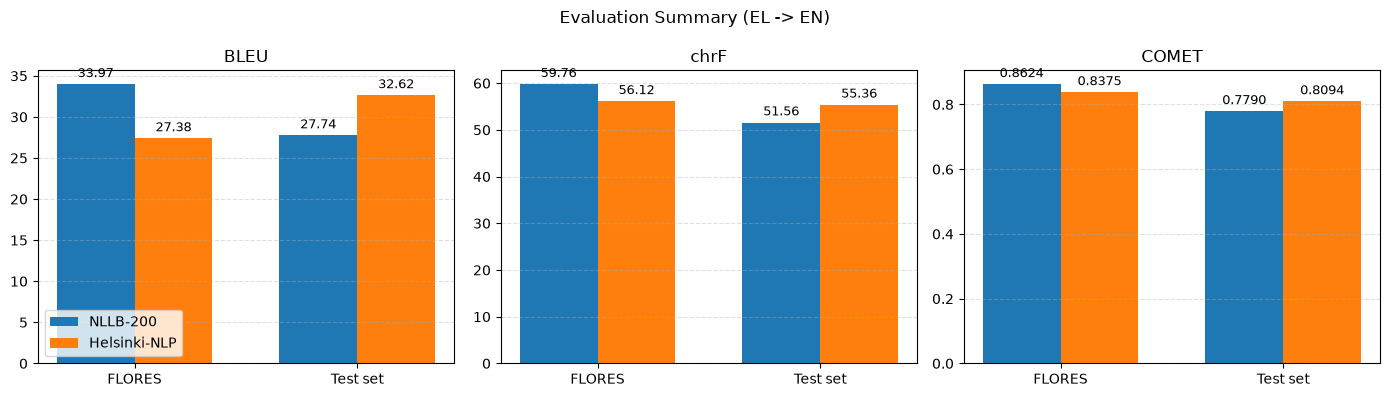

In [37]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
datasets = ["FLORES", "Test set"]
models = ["facebook/nllb-200-distilled-600M", "Helsinki-NLP/opus-mt-grk-en"]
short_names = ["NLLB-200", "Helsinki-NLP"]
x = range(len(datasets))
width = 0.35

for ax, metric in zip(axes, ["BLEU", "chrF", "COMET"]):
    for i, (model, label) in enumerate(zip(models, short_names)):
        vals = [results_df[(results_df["Dataset"] == d) & (results_df["Model"] == model)][metric].values[0] for d in datasets]
        bars = ax.bar([p + i * width for p in x], vals, width, label=label)
        fmt = "{:.4f}" if metric == "COMET" else "{:.2f}"
        ax.bar_label(bars, labels=[fmt.format(v) for v in vals], padding=3, fontsize=9)
    ax.set_title(metric)
    ax.set_xticks([p + width / 2 for p in x])
    ax.set_xticklabels(datasets)
    ax.grid(axis="y", linestyle="--", alpha=0.4)

axes[0].legend()
fig.suptitle("Evaluation Summary (EL -> EN)")
plt.tight_layout()
plt.savefig("evaluation_summary.png")
plt.show()

## 2.5.4 Αξιολόγηση εμπορικών συστημάτων (Test set)

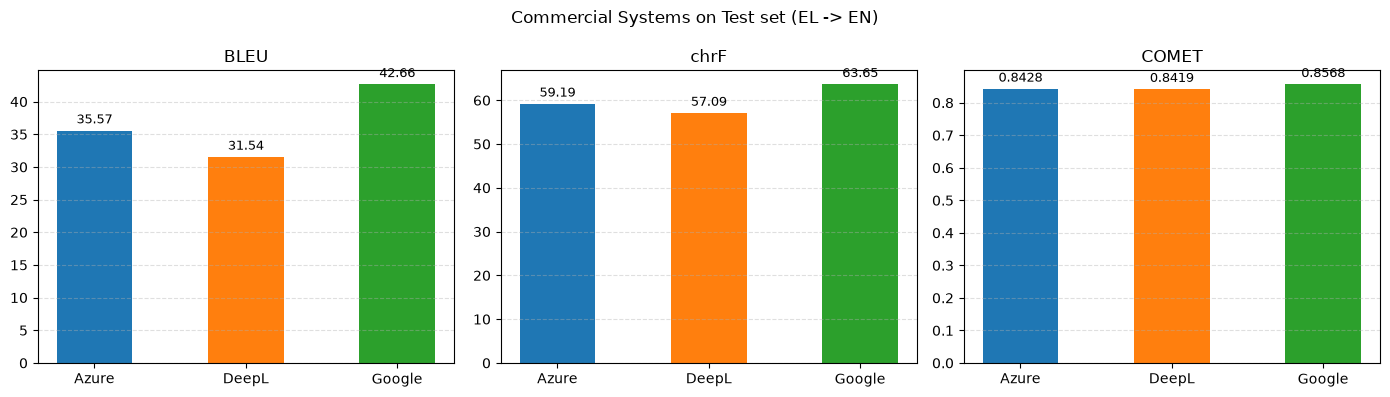

In [38]:
commercial = results_df[results_df["Model"].isin(["Azure", "DeepL", "Google"])]

fig, axes = plt.subplots(1, 3, figsize=(14, 4))

for ax, metric in zip(axes, ["BLEU", "chrF", "COMET"]):
    bars = ax.bar(commercial["Model"], commercial[metric], width=0.5, color=["tab:blue", "tab:orange", "tab:green"])
    fmt = "{:.4f}" if metric == "COMET" else "{:.2f}"
    ax.bar_label(bars, labels=[fmt.format(v) for v in commercial[metric]], padding=3, fontsize=9)
    ax.set_title(metric)
    ax.grid(axis="y", linestyle="--", alpha=0.4)

fig.suptitle("Commercial Systems on Test set (EL -> EN)")
plt.tight_layout()
plt.savefig("evaluation_commercial.png")
plt.show()

## 2.5.5 Παραδείγματα μεταφράσεων (5 χαμηλότερα chrF ανά test set)

In [39]:
import sacrebleu

pd.set_option("display.max_colwidth", None)

# FLORES: 5 προτάσεις με το χαμηλότερο chrF
flores_scores = []
for i in range(len(source)):
    s_nllb = sacrebleu.sentence_chrf(fb_nllb[i].lower(), [ref[i].lower()]).score
    s_helsinki = sacrebleu.sentence_chrf(helsinki_nlp[i].lower(), [ref[i].lower()]).score
    flores_scores.append((min(s_nllb, s_helsinki), i, s_nllb, s_helsinki))

flores_scores.sort()

rows = []
for n, (_, i, s_nllb, s_helsinki) in enumerate(flores_scores[:5], 1):
    rows.append((n, "Source (greek)", source[i], ""))
    rows.append((n, "Reference (EN)", ref[i], ""))
    rows.append((n, "NLLB-200", fb_nllb[i], round(s_nllb, 2)))
    rows.append((n, "Helsinki-NLP", helsinki_nlp[i], round(s_helsinki, 2)))

flores_examples = pd.DataFrame(rows, columns=["#", "Model", "Text", "chrF"]).set_index(["#", "Model"])
flores_examples

Text  \
# Model                                                                                                                                                                                                                          
1 Source (greek)          Το όπλο του Γιούκα αστόχησε, καθώς ήταν στραμμένο στο κεφάλι ενός άντρα. Ο Σνάιντερ υφίσταται διαρκή πόνο, τύφλωση στο ένα μάτι, απώλεια τμήματος του κρανίου και αναδόμηση του προσώπου με τιτάνιο.   
  Reference (EN)                                      Uka's weapon failed whilst pointed at a fifth man's head. Schneider has ongoing pain, blindness in one eye, a missing section of skull and a face rebuilt from titanium.   
  NLLB-200        Yuka's gun went off as it was pointed at a man's head, and Snyder is suffering from chronic pain, blindness in one eye, loss of a fraction of his skull, and renal reconstruction of his face with titanium.   
  Helsinki-NLP                                                                                                                                                              Yuka's gun missed, as it was on the head of a man.   
2 Source (greek)                                                                                                        Αλλάζει κατά πολύ επίσης η όρεξη των αλλοδαπών διακυβερνήσεων να σε σεβαστούν τα συγκεκριμένα έγγραφα.   
  Reference (EN)                                                                                                                      Willingness of foreign governments to honour these documents is just as widely variable.   
  NLLB-200                                                                                                                                     The Commission has also been able to make a number of proposals to the Council.   
  Helsinki-NLP                                                                                                                        The desire for foreign governments to respect these documents is also very much changed.   
3 Source (greek)                                                                                                                                    Έτσι ξεχωρίζουν με βάση έναν κανόνα οι ρηματικοί τύποι από τα αντικείμενα.   
  Reference (EN)                                                                                                                                       This is an important way to distinguish between some verbs and objects.   
  NLLB-200                                                                                                                                           So they're going to tell the rhetorical types from the objects by a rule.   
  Helsinki-NLP                                                                                                                                       This is how commercial types of objects stand out on the basis of a rule.   
4 Source (greek)                                                                                                      Αρχικά οι πιο πολλοί ιππείς διαθέτουν ειδικά παπούτσια που έχουν τακούνια, απαλό και σχετικά μικρό πάτο.   
  Reference (EN)                                                                                                                            First, most riders wear riding boots with a heel and a smooth, quite narrow, sole.   
  NLLB-200                                                                                                                              Initially, most riders have special shoes with heels, a soft, relatively small bottom.   
  Helsinki-NLP                                                                                                                                  Initially most horsemen have special heels, soft and relatively small bottoms.   
5 Source (greek)                                              Όσο πιο λίγη είναι η πίεση, τόσο πιο καλύτερη είναι η ζωτική δύναμη που είναι παρούσα. Κ

In [40]:
# Δικό μας Test set: 5 προτάσεις με το χαμηλότερο chrF
test_scores = []
for i in range(len(test_source)):
    s_nllb = sacrebleu.sentence_chrf(fb_nllb_test[i].lower(), [test_ref[i].lower()]).score
    s_helsinki = sacrebleu.sentence_chrf(helsinki_nlp_test[i].lower(), [test_ref[i].lower()]).score
    s_azure = sacrebleu.sentence_chrf(azure_translations[i].lower(), [test_ref[i].lower()]).score
    s_deepl = sacrebleu.sentence_chrf(deepl_translations[i].lower(), [test_ref[i].lower()]).score
    s_google = sacrebleu.sentence_chrf(google_translations[i].lower(), [test_ref[i].lower()]).score
    test_scores.append((min(s_nllb, s_helsinki, s_azure, s_deepl, s_google), i, s_nllb, s_helsinki, s_azure, s_deepl, s_google))

test_scores.sort()

rows = []
for n, (_, i, s_nllb, s_helsinki, s_azure, s_deepl, s_google) in enumerate(test_scores[:5], 1):
    rows.append((n, "Source (greek)", test_source[i], ""))
    rows.append((n, "Reference (EN)", test_ref[i], ""))
    rows.append((n, "NLLB-200", fb_nllb_test[i], round(s_nllb, 2)))
    rows.append((n, "Helsinki-NLP", helsinki_nlp_test[i], round(s_helsinki, 2)))
    rows.append((n, "Azure", azure_translations[i], round(s_azure, 2)))
    rows.append((n, "DeepL", deepl_translations[i], round(s_deepl, 2)))
    rows.append((n, "Google", google_translations[i], round(s_google, 2)))

test_examples = pd.DataFrame(rows, columns=["#", "Model", "Text", "chrF"]).set_index(["#", "Model"])
test_examples

Text  \
# Model                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                               
1 Source (greek)                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                          # Διπλωματική εργασία # Πολυτεχνείο Κρήτης / Σχολή Αρχιτεκτόνων Μηχανικών   
  Reference (EN)                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                          